In [26]:
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 


In [27]:
uproot.__version__, pd.__version__, np.__version__, xgboost.__version__

('4.3.7', '1.5.3', '1.23.5', '2.0.2')

In [28]:
# Set of variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  




In [29]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [30]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)

df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [31]:
df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


# Training with WP85

In [32]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)



In [33]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)

2804

In [34]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)

3051

In [35]:
df_sig_85_reweighted = df_sig_85

In [36]:
# Calculate the mean of negative values in the 'weight' column
mean_negative_weights = df_bkg_fakes_ttyprodNLO_85[df_bkg_fakes_ttyprodNLO_85['weight'] < 0]['weight'].mean()
print(f"Mean neg weight: {mean_negative_weights}")
# Filter and print values less than the mean of negative values
print(df_bkg_fakes_ttyprodNLO_85[df_bkg_fakes_ttyprodNLO_85['weight'] < mean_negative_weights]['weight'])

Mean neg weight: -0.01699763350188732
entry
0      -0.023602
1      -0.018001
17     -0.017715
25     -0.019851
29     -0.018626
          ...   
2130   -0.018008
2133   -0.022136
2137   -0.019714
2139   -0.017308
2144   -0.018256
Name: weight, Length: 320, dtype: float32


In [58]:
n_estimators = 100

In [59]:

nfolds = 4

models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
 

    print(f"\nFold: {fold}")
    
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]

 
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    
    

    print(f"\n\nFold {fold}:")
    print(f"Signal: {len(X_sig_train)} train, {len(X_sig_test)} test")
    print(f"Prompt Background: {len(X_bkg_train_prompts)} train, {len(X_bkg_test_prompts)} test")
    print(f"Fake Background: {len(X_bkg_train_fakes)} train, {len(X_bkg_test_fakes)} test")


    
    # Check weight sums
    print(f"Total training weight: {np.sum(w_train)}, Total testing weight: {np.sum(w_test)}")
    print(f"Class 0 weight sum: Train = {np.sum(w_train[y_train == 0])}, Test = {np.sum(w_test[y_test == 0])}")
    print(f"Class 1 weight sum: Train = {np.sum(w_train[y_train == 1])}, Test = {np.sum(w_test[y_test == 1])}")
    print(f"Class 2 weight sum: Train = {np.sum(w_train[y_train == 2])}, Test = {np.sum(w_test[y_test == 2])}")
    


    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     
        verbosity=2,            
        n_estimators=n_estimators, 
        #objective="multi:softmax",  
        #num_class=3             
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test)))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
                           



Fold: 0


Fold 0:
Signal: 269250 train, 89637 test
Prompt Background: 2100 train, 704 test
Fake Background: 2303 train, 748 test
Total training weight: 58.138614654541016, Total testing weight: 19.478897094726562
Class 0 weight sum: Train = 34.109214782714844, Test = 11.372666358947754
Class 1 weight sum: Train = 7.0282182693481445, Test = 2.8055293560028076
Class 2 weight sum: Train = 17.001178741455078, Test = 5.3007025718688965
Train scores 0: [0.7380590918990813]
Test scores 0:  [0.6207718373417707]

Fold: 1


Fold 1:
Signal: 269313 train, 89574 test
Prompt Background: 2106 train, 698 test
Fake Background: 2321 train, 730 test
Total training weight: 58.975006103515625, Total testing weight: 18.64250946044922
Class 0 weight sum: Train = 34.14506149291992, Test = 11.336824417114258
Class 1 weight sum: Train = 7.723145484924316, Test = 2.110602617263794
Class 2 weight sum: Train = 17.106800079345703, Test = 5.19508171081543
Train scores 1: [0.7380590918990813, 0.73779941988118]
Test 

In [60]:
# Testing loss curve - 06.02.2025

n_estimators = 100
nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        #print(f"\nFold: {fold}")
    
        X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
        w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]

        X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
        w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]

        X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
        w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

        X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]

        X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
        w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

        X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
        w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]


        y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
        X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
        w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
        y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
        X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
        w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])


        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)


In [61]:
mplhep.style.use('ATLAS')

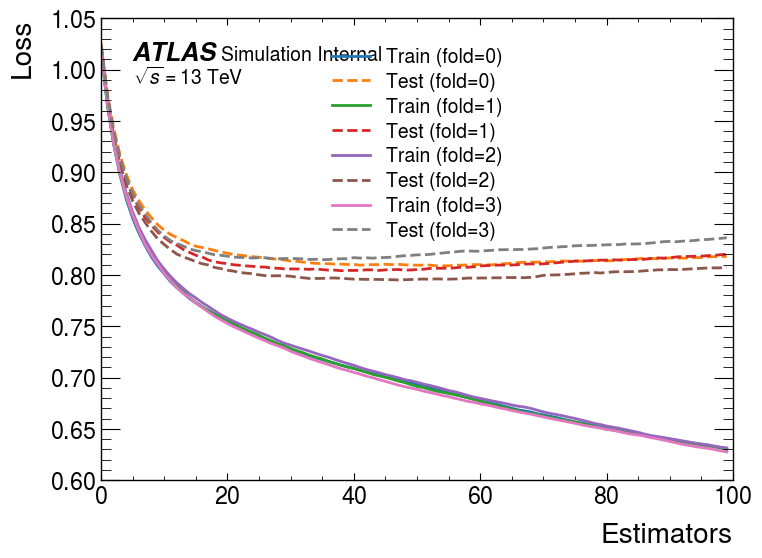

In [88]:
nfolds = 4
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(loc='best')
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
#plt.savefig('loss_3class_100est.pdf')
plt.show()

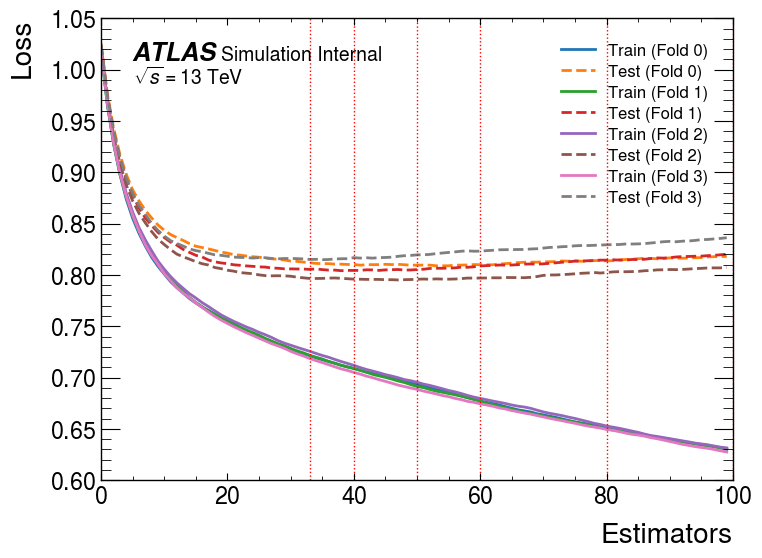

In [96]:
nfolds = 4
highlight_estimators = [33, 40, 50, 60, 80, 100]  # Points where vertical lines will be drawn

# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train (Fold {fold})')
    ax.plot(estimators, testloss[fold], label=f'Test (Fold {fold})', linestyle='--')

# Add vertical lines at selected estimator values
for est in highlight_estimators:
    ax.axvline(est, color='red', linestyle=':', linewidth=1)  # Adjust color, linestyle, and width as needed

ax.legend(fontsize=12)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # Set True to remove 'Simulation'
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
#plt.savefig('loss_3class_100est.pdf')
# Show the plot
plt.show()

In [68]:
avg_test_loss = np.mean([np.array(testloss[fold]) for fold in range(nfolds)], axis=0)

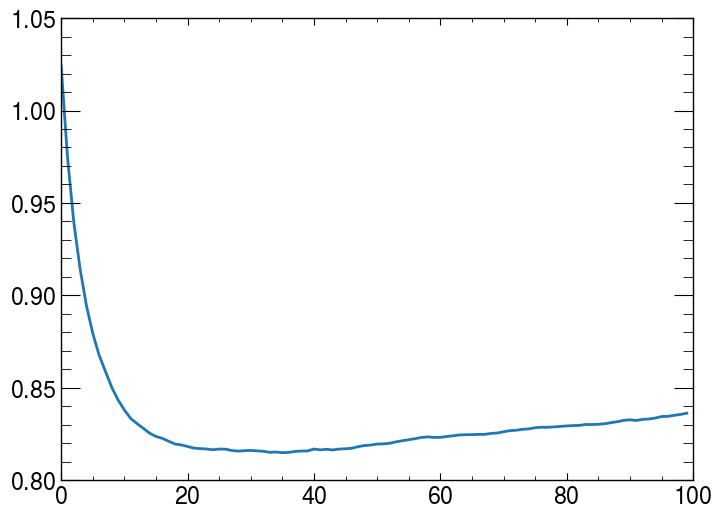

In [69]:
plt.plot(estimators, testloss[fold])

In [70]:
from scipy.interpolate import CubicSpline

In [78]:
s = CubicSpline(estimators, avg_test_loss)

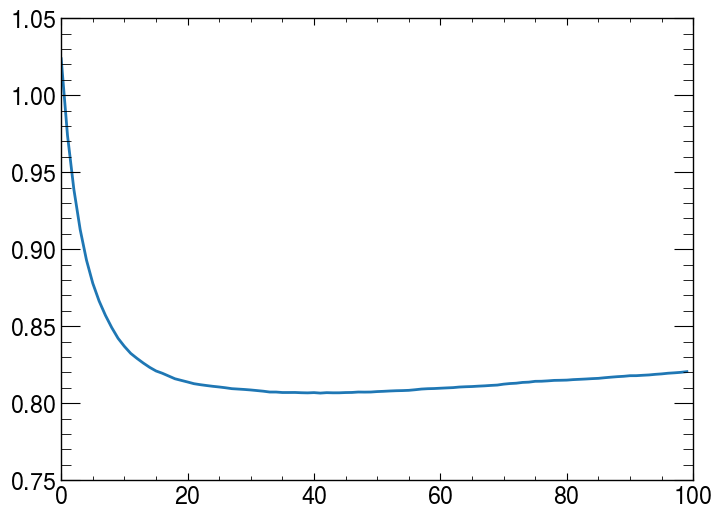

In [82]:
plt.plot(estimators, s(estimators))

In [83]:
x_mins = s1.derivative().roots()

In [87]:
x_mins[np.argmin(s(x_mins))]

41.01928150390063

In [ ]:
import matplotlib.pyplot as plt

nfolds = 4
highlight_estimators = [33, 40, 50, 60, 80, 100]  # Points where vertical lines will be drawn

# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train (Fold {fold})')
    ax.plot(estimators, testloss[fold], label=f'Test (Fold {fold})', linestyle='--')

# Add vertical lines at selected estimator values
for est in highlight_estimators:
    ax.axvline(est, color='gray', linestyle=':', linewidth=1)  # Adjust color, linestyle, and width as needed

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # Set True to remove 'Simulation'
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')

# Show the plot
plt.show()

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

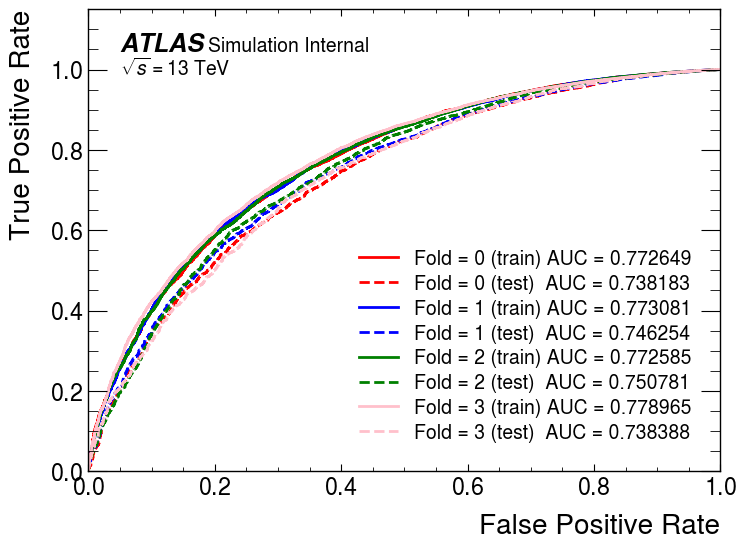

In [57]:
colors = ['red','blue','green','pink'] 
for fold in range(nfolds):
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]

 
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),1 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),1 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    results_train = models[fold].predict_proba(X_train)[:,0]
    results_test = models[fold].predict_proba(X_test)[:,0]

    fpr, tpr, thresholds = metrics.roc_curve(y_train, results_train, pos_label=0)
    AUC = 1 - metrics.roc_auc_score(y_train, results_train)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.6f}', color=colors[fold])

    fpr, tpr, thresholds = metrics.roc_curve(y_test, results_test, pos_label=0)
    AUC = 1 - metrics.roc_auc_score(y_test, results_test)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.6f}', color=colors[fold], linestyle='--')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)
#plt.savefig('auc.png')